In [45]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch, SqrtStretch, LinearStretch
from scipy.ndimage import gaussian_filter

# CHANGE THIS to your folder of named HR FITS images.
IMAGE_DIR = Path('/Users/gracedavis/ASTRO 320W/Exercise E/EXERCISE E')
REPO = Path.cwd().parent       # Open this notebook from notebooks/.
DATA_DIR = REPO / 'data'
OUTPUT_DIR = REPO / 'results'
OUTPUT_DIR.mkdir(exist_ok=True)

FILES = {
    'HR5618': 'CCD Image 8.fit',
    'HR6200': 'HR6200_1.fit',
    'HR6212': 'HR6212_1.fit',
    'HR6446': 'HR6446_1.fit',
    'HR7310': 'HR7310_1.fit',
    'HR7751': 'HR7751_1.fit',
    'HR7942': 'HR7942_1.fit',
    'HR7947': 'HR7947_1.fit',
    'HR8285': 'HR8285_1.fit',
    'HR8815': 'HR8815_1.fit',
}

# EDIT EACH TARGET HERE. All limits are in DN.
# stretch can be 'linear', 'asinh', or 'sqrt'.
# asinh_a controls the curve only when stretch='asinh'.
# half_width=None keeps the automatic crop; use a number to change it.
DISPLAY = {
    # HR5618: change these values to adjust this image.
    'HR5618': {
        'min_dn': 140,
        'max_dn': 48000,
        'stretch': 'asinh',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR6200: change these values to adjust this image.
    'HR6200': {
        'min_dn': 50,
        'max_dn': 700,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR6212: change these values to adjust this image.
    'HR6212': {
        'min_dn': 140,
        'max_dn': 48000,
        'stretch': 'asinh',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR6446: change these values to adjust this image.
    'HR6446': {
        'min_dn': 250,
        'max_dn': 400,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR7310: change these values to adjust this image.
    'HR7310': {
        'min_dn': 95,
        'max_dn': 390,
        'stretch': 'linear',
        'asinh_a': 0.002,
        'half_width': None,
    },

    # HR7751: change these values to adjust this image.
    'HR7751': {
        'min_dn': 140,
        'max_dn': 600,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR7942: change these values to adjust this image.
    'HR7942': {
        'min_dn': 136,
        'max_dn': 400,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR7947: change these values to adjust this image.
    'HR7947': {
        'min_dn': 140,
        'max_dn': 500,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR8285: change these values to adjust this image.
    'HR8285': {
        'min_dn': 140,
        'max_dn': 450,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

    # HR8815: change these values to adjust this image.
    'HR8815': {
        'min_dn': 140,
        'max_dn': 500,
        'stretch': 'linear',
        'asinh_a': 0.01,
        'half_width': None,
    },

}

SHOW_LABELS = True
SAVE_FIGURE = True


In [46]:
with (DATA_DIR / 'newE.csv').open() as f:
    initial = {r['Label'].split('_')[0]: r for r in csv.DictReader(f)}
with (DATA_DIR / 'E_verified_repeats.csv').open() as f:
    pairs = {r['target']: r for r in csv.DictReader(f) if r['image'] == '1'}

# Coordinates use the original FITS array orientation.
COORDINATES = {
    name: np.array([[float(r['x1']), 1528-float(r['y1'])],
                    [float(r['x2']), 1528-float(r['y2'])]])
    for name, r in pairs.items()
}
COORDINATES['HR6446'] = np.array([[1073.078, 822.104],
                                 [1063.117, 789.218]])
UNRESOLVED = {'HR5618', 'HR6212', 'HR7942', 'HR8285', 'HR7947'}


def draw_target(ax, name):
    image = fits.getdata(IMAGE_DIR / FILES[name]).astype(float)
    pair = COORDINATES.get(name)
    if pair is not None:
        center = pair.mean(axis=0)
        half = max(32, np.max(abs(pair-center))*1.55+15)
    elif name in initial:
        row = initial[name]
        k = 1 if float(row['Peak_1']) >= float(row['Peak_2']) else 2
        center = np.array([float(row[f'X{k}(IJ)']),
                           1528-float(row[f'Y{k}(IJ)'])])
        half = 38
    else:
        smooth = gaussian_filter(image, 2)
        y, x = np.unravel_index(np.argmax(smooth[300:1200, 300:1200]), (900,900))
        center = np.array([x+300, y+300])
        half = 38
    settings = DISPLAY[name]
    if settings['half_width'] is not None:
        half = float(settings['half_width'])
    x, y = center
    x0, x1 = max(0,int(x-half)), min(image.shape[1],int(x+half+1))
    y0, y1 = max(0,int(y-half)), min(image.shape[0],int(y+half+1))
    crop = image[y0:y1, x0:x1]
    lo = np.nanmedian(crop) if settings['min_dn'] is None else settings['min_dn']
    hi = np.nanpercentile(crop,99.8) if settings['max_dn'] is None else settings['max_dn']
    if not hi > lo:
        raise ValueError(f'{name}: max_dn must be greater than min_dn')
    mode = settings['stretch']
    stretches = {'linear': LinearStretch(), 'sqrt': SqrtStretch(),
                  'asinh': AsinhStretch(a=settings['asinh_a'])}
    if mode not in stretches:
        raise ValueError('stretch must be linear, asinh, or sqrt')
    norm = ImageNormalize(vmin=lo, vmax=hi, stretch=stretches[mode], clip=True)
    ax.imshow(crop, origin='lower', cmap='gray', norm=norm,
              extent=[x0-.5,x1-.5,y0-.5,y1-.5], interpolation='nearest')
    if SHOW_LABELS and pair is not None:
        for point, label, color in zip(pair,['A','B'],['#48ddff','#ffbb55']):
            ax.annotate(label, point, xytext=(10,10), textcoords='offset points',
                        color=color, fontsize=16, fontweight='bold',
                        arrowprops=dict(arrowstyle='-', color=color, lw=.8))
    title = name + (' — Unresolved' if name in UNRESOLVED else '')
    ax.set_title(title, fontsize=14.5)
    ax.set_xticks([]); ax.set_yticks([])
    return lo, hi


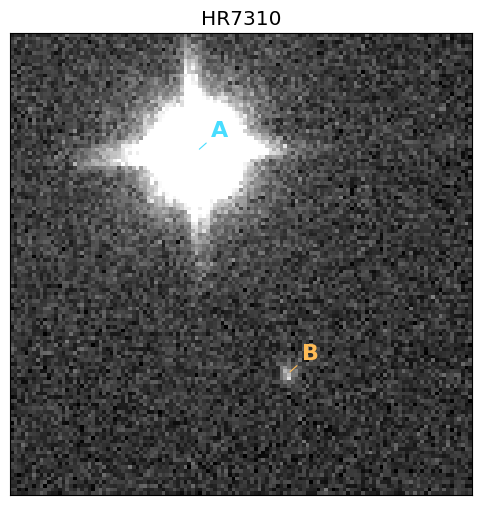

HR7310: min = 95.00 DN; max = 390.00 DN


In [47]:
# Choose one target while adjusting its limits above.
PREVIEW_TARGET = 'HR7310'
fig, ax = plt.subplots(figsize=(6,6))
lo, hi = draw_target(ax, PREVIEW_TARGET)
plt.show()
print(f'{PREVIEW_TARGET}: min = {lo:.2f} DN; max = {hi:.2f} DN')


HR5618: CCD Image 8.fit | min=140.00, max=48000.00 DN
HR6200: HR6200_1.fit | min=50.00, max=700.00 DN
HR6212: HR6212_1.fit | min=140.00, max=48000.00 DN
HR6446: HR6446_1.fit | min=250.00, max=400.00 DN
HR7310: HR7310_1.fit | min=95.00, max=390.00 DN
HR7751: HR7751_1.fit | min=140.00, max=600.00 DN
HR7942: HR7942_1.fit | min=136.00, max=400.00 DN
HR7947: HR7947_1.fit | min=140.00, max=500.00 DN
HR8285: HR8285_1.fit | min=140.00, max=450.00 DN
HR8815: HR8815_1.fit | min=140.00, max=500.00 DN
Saved: /Users/gracedavis/Documents/Codex/2026-10-19/oth/outputs/Artemis_ASTRO320W_GitHub/results/E_observed_fields.png


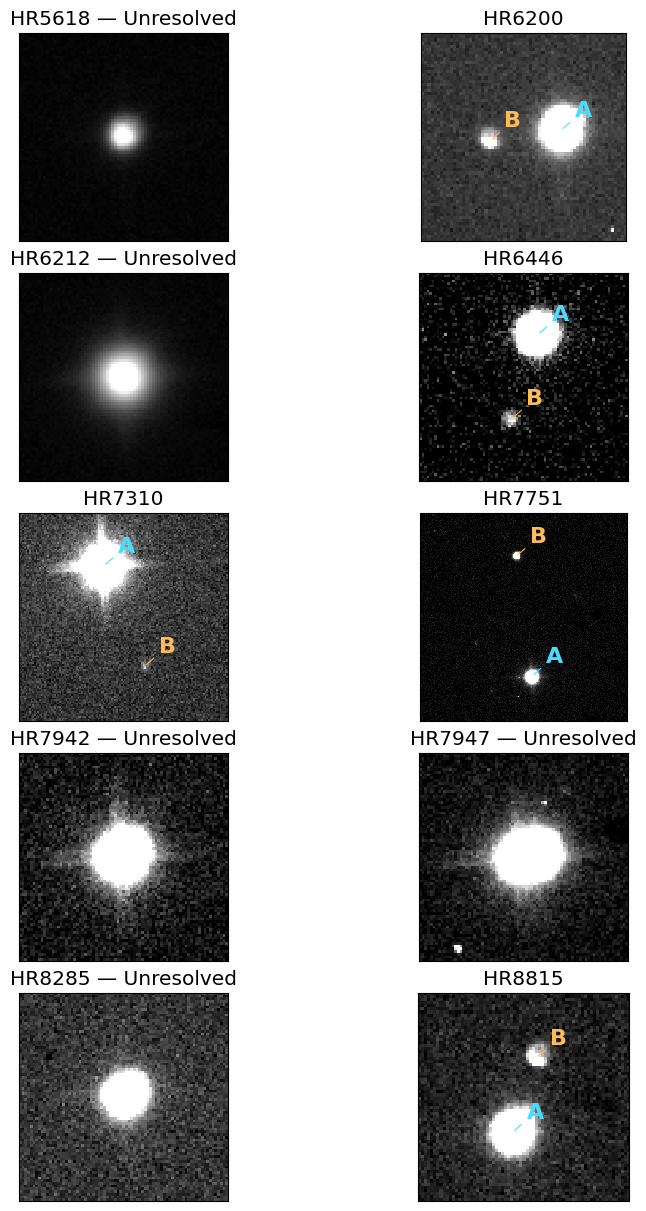

In [48]:
fig, axes = plt.subplots(5,2,figsize=(8,12),layout='constrained')
for ax, name in zip(axes.flat, FILES):
    lo, hi = draw_target(ax, name)
    print(f'{name}: {FILES[name]} | min={lo:.2f}, max={hi:.2f} DN')
if SAVE_FIGURE:
    output = OUTPUT_DIR / 'E_observed_fields.png'
    fig.savefig(output, dpi=240)
    print('Saved:', output)
plt.show()
